# WiFi CSI Sensing
# Track A: Human Activity Recognition (HAR) & Gesture Recognition
**Tugas Project Pengganti UTS — Pembelajaran Mesin Lanjut**

Kelompok: `13`
Anggota :
1. `Faiz Ramadhan Suhanda`
2. `M. Arland Hillery`
3. `Aditya Rahmat`
4. `Abdullah Azzam Assyafiqi`

Notebook ini membangun pipeline lengkap **raw CSI kompleks → preprocessing → Deep Learning → evaluasi → demo inferensi** untuk mengenali **276 gestur bahasa isyarat** dari sinyal WiFi CSI menggunakan dataset **SignFi** (Ma et al., 2018; Intel 5300, 3 antena × 30 subcarrier, 200 paket per gestur). SignFi adalah salah satu dataset yang direkomendasikan untuk Track A dan tercantum di repo *Awesome-WiFi-CSI-Sensing*.

SignFi menyimpan **CSI dalam bentuk bilangan kompleks mentah**, sehingga seluruh tahap preprocessing pada panduan tugas (termasuk *phase sanitization*) benar-benar bisa dan harus diterapkan.

### Alur pipeline (setiap tahap dipakai & diaudit)

| # | Tahap (sesuai panduan) | Implementasi | Dipakai oleh |
|---|---|---|---|
| 1 | **Extraction** | matriks kompleks $H$ (N×200×3×30) → amplitudo `abs(H)` & fase `angle(H)` | semua model |
| 2 | **Filtering noise** | **DWT denoising** (db4, soft-threshold universal) **+ Butterworth low-pass** orde 4 zero-phase (`filtfilt`) di sumbu waktu | semua model |
| 3 | **Phase sanitization** | *unwrapping* lintas subcarrier + **transformasi linier** $\hat\phi_k=\phi_k-ak-b$ (hapus error STO/SFO & CFO) | kanal fase semua model |
| 4 | **Feature structuring** | **tensor (Batch, Channels=2, Subcarriers=90, Time=200)** dan **PCA + STFT spektrogram** (Batch, 8, 17, 43) | 1D-CNN & CNN-BiLSTM (tensor), ResNet-2D (spektrogram) |

**Model yang dibandingkan:** (1) *Baseline* 1D-CNN, (2) *Proposed* CNN-BiLSTM + Attention, (3) ResNet-2D pada spektrogram STFT.
**Ablation study:** efek tiap tahap preprocessing (tanpa filter, tanpa sanitization, amplitudo saja, fase saja, raw).

> ⚙️ **Sebelum mulai:** `Runtime → Change runtime type → T4 GPU`, lalu `Runtime → Run all`. Estimasi total ±30–45 menit.

## 1. Setup environment

In [ ]:
!pip -q install PyWavelets h5py

import os, sys, glob, json, time, random, shutil, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
warnings.filterwarnings('ignore')

BASE_DIR = '/content' if os.path.isdir('/content') else os.getcwd()
PROJECT_DIR = os.path.join(BASE_DIR, 'wifi-csi-har')
os.makedirs(os.path.join(PROJECT_DIR, 'src'), exist_ok=True)
open(os.path.join(PROJECT_DIR, 'src', '__init__.py'), 'a').close()
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch :', torch.__version__)
print('Device  :', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU (disarankan ganti ke GPU)')
print('Project :', PROJECT_DIR)

PyTorch : 2.11.0+cu130
Device  : cuda | Tesla T4
Project : /content/wifi-csi-har


## 2. Konfigurasi eksperimen
Semua hyperparameter dikumpulkan di satu tempat agar eksperimen *reproducible* (disimpan ke `outputs/config.json`).

In [ ]:
CFG = dict(
    # --- data ---
    DATA_ROOT   = os.path.join(BASE_DIR, 'data_signfi'),
    SIGNFI_FILE = 'dataset_lab_276_dl.mat',          # 5.520 sampel, 276 gestur, 20 sampel/kelas
    OUT_DIR     = os.path.join(PROJECT_DIR, 'outputs'),
    MAX_CLASSES = None,      # isi angka (mis. 50) untuk uji cepat dengan subset kelas

    # --- karakteristik sinyal ---
    FS = 200.0,              # nominal (200 paket per gestur); filter didefinisikan relatif terhadap FS ini
    N_ANT = 3, N_SUB = 30,

    # --- tahap 2: filtering ---
    DWT_WAVELET = 'db4', DWT_LEVEL = 2,
    LPF_CUTOFF  = 40.0, LPF_ORDER = 4,   # 40 Hz dari Nyquist 100 Hz (0.4 normalized)

    # --- tahap 4: feature structuring ---
    N_PCA = 4, STFT_NPERSEG = 32, STFT_NOVERLAP = 28,

    # --- training ---
    SPLIT = (0.70, 0.15, 0.15),          # stratified per kelas -> 14/3/3 sampel per gestur
    BATCH = 64, EPOCHS = 60, LR = 1e-3, WD = 1e-4, PATIENCE = 15, LABEL_SMOOTHING = 0.1,
    AUGMENT = True,
    RUN_ABLATION = True, ABL_EPOCHS = 40, ABL_SEEDS = [42, 2026],
    NUM_WORKERS = 2, SEED = 42,
)
os.makedirs(CFG['OUT_DIR'], exist_ok=True)
FIG_DIR = os.path.join(CFG['OUT_DIR'], 'figures'); os.makedirs(FIG_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(CFG['SEED'])

def savefig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path, dpi=300, bbox_inches='tight')
    print('💾 disimpan:', path)

with open(os.path.join(CFG['OUT_DIR'], 'config.json'), 'w') as f:
    json.dump(CFG, f, indent=2)
print('Konfigurasi tersimpan.')

Konfigurasi tersimpan.


## 3. Dataset SignFi
File `dataset_lab_276_dl.mat` (1,44 GB) dihosting di Box oleh penulis: https://wm1693.box.com/s/z9vsrn3998n4xyzkpqtj89yclk28eatp

Sel di bawah mencoba mengunduh otomatis. **Jika gagal**, lakukan cara manual (±5 menit):
1. Buka link Box di atas di browser → klik **Download**.
2. Upload file `dataset_lab_276_dl.mat` ke **Google Drive → My Drive** (folder mana saja).
3. Jalankan ulang sel ini → Drive akan di-*mount* dan file dicari otomatis.

In [ ]:
DATA_ROOT = CFG['DATA_ROOT']; os.makedirs(DATA_ROOT, exist_ok=True)
MAT_PATH = os.path.join(DATA_ROOT, CFG['SIGNFI_FILE'])
BOX_ID = {'dataset_lab_276_dl.mat': 'z9vsrn3998n4xyzkpqtj89yclk28eatp',
          'dataset_lab_276_ul.mat': '5hr4u7lsj10c329oibp8fjv95i524tnl',
          'dataset_home_276.mat'  : 'mmikgi9ubkg7vnwaztplnxudh8sgj1np'}

def is_valid_mat(p):
    if not os.path.exists(p) or os.path.getsize(p) < 50e6: return False
    with open(p, 'rb') as f: head = f.read(128)
    return head.startswith(b'MATLAB') or head[:8] == b'\x89HDF\r\n\x1a\n' or b'MATLAB' in head

def try_download(dst):
    import requests
    sid = BOX_ID.get(CFG['SIGNFI_FILE'])
    if sid is None: return False
    urls = [f'https://wm1693.box.com/shared/static/{sid}.mat',
            f'https://wm1693.app.box.com/shared/static/{sid}.mat',
            f'https://app.box.com/shared/static/{sid}.mat',
            f'https://wm1693.box.com/shared/static/{sid}']
    for u in urls:
        try:
            print('⬇️', u)
            with requests.get(u, stream=True, timeout=60, allow_redirects=True) as r:
                r.raise_for_status()
                total = int(r.headers.get('content-length', 0)); done = 0
                with open(dst, 'wb') as f:
                    for chunk in r.iter_content(1 << 22):
                        f.write(chunk); done += len(chunk)
                        if total: print(f'\r   {done/1e6:,.0f}/{total/1e6:,.0f} MB', end='')
            print()
            if is_valid_mat(dst): return True
            print('   bukan file .mat yang valid (kemungkinan halaman HTML)')
        except Exception as e:
            print('   gagal:', repr(e)[:200])
    if os.path.exists(dst): os.remove(dst)
    return False

def search_drive(fname):
    try:
        from google.colab import drive
    except ImportError:
        return None
    if not os.path.isdir('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    hits = [h for h in glob.glob('/content/drive/MyDrive/**/' + fname, recursive=True) if is_valid_mat(h)]
    hits += [h for h in glob.glob('/content/drive/MyDrive/**/*.mat', recursive=True)
             if 'signfi' in h.lower() or os.path.basename(h).startswith('dataset_')]
    hits = [h for h in hits if is_valid_mat(h)]
    return hits[0] if hits else None

if not is_valid_mat(MAT_PATH):
    if not try_download(MAT_PATH):
        print('\n⚠️ Unduh otomatis gagal → mencari file di Google Drive ...')
        found = search_drive(CFG['SIGNFI_FILE'])
        if found is None:
            raise RuntimeError(
                'File SignFi belum ada.\n1) Buka https://wm1693.box.com/s/z9vsrn3998n4xyzkpqtj89yclk28eatp -> Download\n'
                '2) Upload dataset_lab_276_dl.mat ke Google Drive (My Drive)\n3) Jalankan ulang sel ini')
        print('📁 ditemukan di Drive:', found)
        MAT_PATH = found
print('✅ File dataset:', MAT_PATH, f'({os.path.getsize(MAT_PATH)/1e9:.2f} GB)')

⬇️ https://wm1693.box.com/shared/static/z9vsrn3998n4xyzkpqtj89yclk28eatp.mat

✅ File dataset: /content/data_signfi/dataset_lab_276_dl.mat (1.44 GB)


## 4. Modul preprocessing CSI (`src/preprocessing.py`)
Modul ditulis ke file `.py` agar langsung dipakai di repositori GitHub. Setiap fungsi tahap mencatat pemanggilannya ke `STEP_LOG` → di bagian 6.1 kita **mengaudit** bahwa semua tahap benar-benar terpakai pada data yang masuk ke model.

**Catatan urutan:** pada fase, **sanitization dilakukan sebelum filtering**, karena fase mentah mengandung offset acak per paket (CFO/STO). Jika langsung di-*low-pass*, offset acak itu ikut “dihaluskan” dan informasi gerakan rusak.

Rumus phase sanitization (Sen et al., MobiSys 2012; Qian et al.): untuk paket ke-*t* dan antena ke-*m*, setelah fase di-*unwrap* lintas subcarrier,
$$a=\frac{\phi_{K}-\phi_{1}}{k_K-k_1},\qquad b=\frac{1}{K}\sum_{i}\phi_i - a\,\bar{k},\qquad \hat\phi_i=\phi_i-a\,k_i-b$$
dengan $k_i$ indeks subcarrier ($-58,-54,\dots,58$ sesuai kode referensi SignFi).

In [ ]:
%%writefile src/preprocessing.py
"""
Pipeline preprocessing WiFi CSI untuk dataset SignFi (Intel 5300, 3 antena x 30 subcarrier).

Tahapan:
 1. Extraction         : matriks CSI kompleks H -> amplitudo |H| dan fase angle(H)
 2. Noise filtering    : DWT denoising (soft threshold) + Butterworth low-pass zero-phase (sumbu waktu)
 3. Phase sanitization : unwrapping lintas subcarrier + transformasi linier (hapus slope STO/SFO & offset CFO)
 4. Feature structuring: tensor (N, C=2, Subcarrier=90, Time) dan spektrogram PCA-STFT
"""
from collections import Counter

import numpy as np
import pywt
from scipy.signal import butter, filtfilt, stft

STEP_LOG = Counter()   # audit: berapa kali tiap tahap dipanggil

SIGNFI_SUBCARRIER_IDX = -58.0 + 4.0 * np.arange(30)   # sesuai kode referensi SignFi (csi_phase_offset.py)

VARIANTS = ("full", "no_filter", "no_sanitize", "raw")


# ----------------------------------------------------------------- I/O
def load_signfi_mat(path, prefer="csid"):
    """Baca file .mat SignFi (v5 atau v7.3/HDF5) -> csi (N, T, ant, sub) complex64, label (N,) mulai 0."""
    try:
        from scipy.io import loadmat
        items = {k: v for k, v in loadmat(path).items() if not k.startswith("__")}
    except NotImplementedError:   # MAT v7.3
        import h5py
        items = {}
        with h5py.File(path, "r") as f:
            for k in f.keys():
                d = f[k][()]
                if getattr(d.dtype, "names", None) and "real" in d.dtype.names:
                    d = d["real"] + 1j * d["imag"]
                items[k] = d
    cands = [k for k, v in items.items() if np.iscomplexobj(v) and np.ndim(v) == 4]
    if not cands:
        raise ValueError(f"Tidak ada array CSI kompleks 4D di {path}. Keys: {list(items)}")
    csi_key = next((k for k in cands if k.lower().startswith(prefer)), cands[0])
    lab_key = next(k for k in items if k.lower().startswith("label"))
    X = np.asarray(items[csi_key])
    y = np.asarray(items[lab_key]).astype(np.int64).ravel()
    shape = list(X.shape)
    ax_n = shape.index(len(y))
    rest = [i for i in range(4) if i != ax_n]
    ax_sub = next(i for i in rest if shape[i] == 30)
    ax_ant = next(i for i in rest if shape[i] == 3 and i != ax_sub)
    ax_t = next(i for i in rest if i not in (ax_sub, ax_ant))
    X = np.ascontiguousarray(np.transpose(X, (ax_n, ax_t, ax_ant, ax_sub)).astype(np.complex64))
    return X, y - y.min(), csi_key, lab_key


# ----------------------------------------------------------------- Tahap 1
def extract_amplitude_phase(H):
    """Tahap 1 - Extraction: amplitudo & fase dari matriks CSI kompleks."""
    STEP_LOG["1_extraction_amp_phase"] += 1
    return np.abs(H).astype(np.float32), np.angle(H).astype(np.float32)


# ----------------------------------------------------------------- Tahap 2
def dwt_denoise(x, wavelet="db4", level=2, axis=1):
    """Tahap 2a - DWT denoising sepanjang sumbu waktu, VisuShrink soft-threshold.
    sigma noise diestimasi dari koefisien detail level terhalus (MAD/0.6745) per deret."""
    STEP_LOG["2a_dwt_denoise"] += 1
    x = np.moveaxis(np.asarray(x, dtype=np.float64), axis, 0)
    shp = x.shape; T = shp[0]
    x2 = x.reshape(T, -1)
    coeffs = pywt.wavedec(x2, wavelet, level=level, axis=0)
    sigma = np.median(np.abs(coeffs[-1]), axis=0) / 0.6745
    thr = sigma * np.sqrt(2.0 * np.log(T))
    den = [coeffs[0]] + [np.sign(c) * np.maximum(np.abs(c) - thr, 0.0) for c in coeffs[1:]]
    rec = pywt.waverec(den, wavelet, axis=0)[:T].reshape(shp)
    return np.moveaxis(rec, 0, axis).astype(np.float32)


def butterworth_lowpass(x, fs, cutoff, order=4, axis=1):
    """Tahap 2b - Butterworth low-pass zero-phase (filtfilt) sepanjang sumbu waktu."""
    STEP_LOG["2b_butterworth_lowpass"] += 1
    b, a = butter(order, cutoff / (fs / 2.0), btype="low")
    return filtfilt(b, a, x, axis=axis).astype(np.float32)


def denoise(x, cfg, axis=1):
    """DWT (buang noise broadband/spike) -> Butterworth LPF (buang komponen > cutoff)."""
    x = dwt_denoise(x, cfg["DWT_WAVELET"], cfg["DWT_LEVEL"], axis=axis)
    return butterworth_lowpass(x, cfg["FS"], cfg["LPF_CUTOFF"], cfg["LPF_ORDER"], axis=axis)


# ----------------------------------------------------------------- Tahap 3
def sanitize_phase(phase, k=SIGNFI_SUBCARRIER_IDX):
    """Tahap 3 - Phase sanitization. phase: [..., n_sub] (radian, wrapped).
    (a) unwrap lintas subcarrier, (b) transformasi linier: hapus slope a & offset b."""
    STEP_LOG["3a_phase_unwrap"] += 1
    unw = np.unwrap(phase.astype(np.float64), axis=-1)
    STEP_LOG["3b_phase_linear_transform"] += 1
    a = (unw[..., -1] - unw[..., 0]) / (k[-1] - k[0])
    b = unw.mean(axis=-1) - a * k.mean()
    return (unw - a[..., None] * k - b[..., None]).astype(np.float32)


# ----------------------------------------------------------------- Tahap 4
def to_tensor(amp, pha):
    """Tahap 4a - amp/pha (N, T, 90) -> (N, Channels=2, Subcarriers=90, Time=T)."""
    STEP_LOG["4a_tensor_structuring"] += 1
    return np.ascontiguousarray(np.stack([amp, pha], axis=1).transpose(0, 1, 3, 2), dtype=np.float32)


def stft_shape(cfg, T):
    hop = cfg["STFT_NPERSEG"] - cfg["STFT_NOVERLAP"]
    return cfg["STFT_NPERSEG"] // 2 + 1, (T - cfg["STFT_NPERSEG"]) // hop + 1


def stft_spectrogram(X, cfg):
    """Tahap 4b - per kanal (amp/fase): PCA lintas 90 subcarrier -> N_PCA komponen -> STFT -> log-magnitude.
    X (N, 2, 90, T) -> (N, 2*N_PCA, F, T_frames)."""
    STEP_LOG["4b_pca_stft_spectrogram"] += 1
    k = cfg["N_PCA"]; out = []
    for c in range(X.shape[1]):
        M = X[:, c].transpose(0, 2, 1).astype(np.float64)          # (N, T, 90)
        M = M - M.mean(axis=1, keepdims=True)                      # buang komponen statis
        _, _, Vt = np.linalg.svd(M, full_matrices=False)           # PCA per sampel (batched)
        pcs = np.einsum("ntf,nkf->nkt", M, Vt[:, :k])              # (N, k, T)
        _, _, Z = stft(pcs, fs=cfg["FS"], nperseg=cfg["STFT_NPERSEG"], noverlap=cfg["STFT_NOVERLAP"],
                       boundary=None, padded=False, axis=-1)        # (N, k, F, frames)
        out.append(np.log1p(np.abs(Z)))
    return np.concatenate(out, axis=1).astype(np.float32)


# ----------------------------------------------------------------- Pipeline
def preprocess_batch(H, cfg, variants=("full",)):
    """H (N, T, ant, sub) kompleks -> {variant: tensor (N, 2, ant*sub, T)} (+ 'S' spektrogram untuk 'full').
    'full'        : tahap 1 + 2 + 3 + 4 (pipeline utama)
    'no_filter'   : tanpa tahap 2           -> ablation
    'no_sanitize' : fase mentah (tanpa 3)   -> ablation
    'raw'         : tanpa tahap 2 & 3       -> ablation
    """
    N, T = H.shape[:2]
    amp, pha_raw = extract_amplitude_phase(H)                                 # Tahap 1
    need_san = any(v in ("full", "no_filter") for v in variants)
    need_flt = any(v in ("full", "no_sanitize") for v in variants)
    pha_san = sanitize_phase(pha_raw).reshape(N, T, -1) if need_san else None   # Tahap 3
    amp = amp.reshape(N, T, -1); pha_raw = pha_raw.reshape(N, T, -1)
    amp_f = denoise(amp, cfg) if need_flt else None                          # Tahap 2
    out = {}
    for v in variants:
        if v == "full":
            a, p = amp_f, denoise(pha_san, cfg)
        elif v == "no_filter":
            a, p = amp, pha_san
        elif v == "no_sanitize":
            a, p = amp_f, denoise(pha_raw, cfg)
        elif v == "raw":
            a, p = amp, pha_raw
        else:
            raise ValueError(v)
        out[v] = to_tensor(a, p)                                              # Tahap 4a
    if "full" in out:
        out["S"] = stft_spectrogram(out["full"], cfg)                         # Tahap 4b
    return out


def preprocess_dataset(H, cfg, variants=("full",), chunk=500, verbose=True):
    """Jalankan preprocess_batch per potongan (hemat RAM) lalu gabungkan."""
    parts = {}
    for i in range(0, len(H), chunk):
        o = preprocess_batch(H[i:i + chunk], cfg, variants)
        for k, v in o.items():
            parts.setdefault(k, []).append(v)
        if verbose:
            print(f"\r   diproses {min(i + chunk, len(H))}/{len(H)}", end="")
    if verbose:
        print()
    return {k: np.concatenate(v) for k, v in parts.items()}

Writing src/preprocessing.py


In [ ]:
import src.preprocessing as P
importlib.reload(P)
t0 = time.time()
H_ALL, y_raw, CSI_KEY, LAB_KEY = P.load_signfi_mat(MAT_PATH)
print(f'Load {time.time()-t0:.0f} s | key CSI = {CSI_KEY}, key label = {LAB_KEY}')
if CFG['MAX_CLASSES']:
    keep = y_raw < CFG['MAX_CLASSES']; H_ALL, y_raw = H_ALL[keep], y_raw[keep]
y_all = y_raw.astype(np.int64)
N_CLASSES = int(y_all.max() + 1)
CLASSES = [f'sign_{i+1:03d}' for i in range(N_CLASSES)]
lbl_csv = glob.glob('/content/drive/MyDrive/**/sign_labels.csv', recursive=True) if os.path.isdir('/content/drive/MyDrive') else []
if lbl_csv:   # opsional: nama kata isyarat dari file sign_labels.csv SignFi
    try:
        names = pd.read_csv(lbl_csv[0], header=None).iloc[:, -1].astype(str).tolist()
        if len(names) >= N_CLASSES: CLASSES = names[:N_CLASSES]
    except Exception: pass
T_LEN = H_ALL.shape[1]
print('CSI kompleks:', H_ALL.shape, H_ALL.dtype, '-> (N, Time, Antena, Subcarrier)')
print('Jumlah kelas:', N_CLASSES, '| sampel per kelas:', np.bincount(y_all).min(), '-', np.bincount(y_all).max())
print('Amplitudo range: %.2f .. %.2f' % (np.abs(H_ALL[:50]).min(), np.abs(H_ALL[:50]).max()))

Load 11 s | key CSI = csid_lab, key label = label_lab
CSI kompleks: (5520, 200, 3, 30) complex64 -> (N, Time, Antena, Subcarrier)
Jumlah kelas: 276 | sampel per kelas: 20 - 20
Amplitudo range: 0.00 .. 194.16


## 5. Visualisasi setiap tahap preprocessing
Memperlihatkan **efek nyata** tiap tahap pada satu sampel (gambar disimpan di `outputs/figures/` untuk laporan).

💾 disimpan: /content/wifi-csi-har/outputs/figures/prep_step2_filtering.png


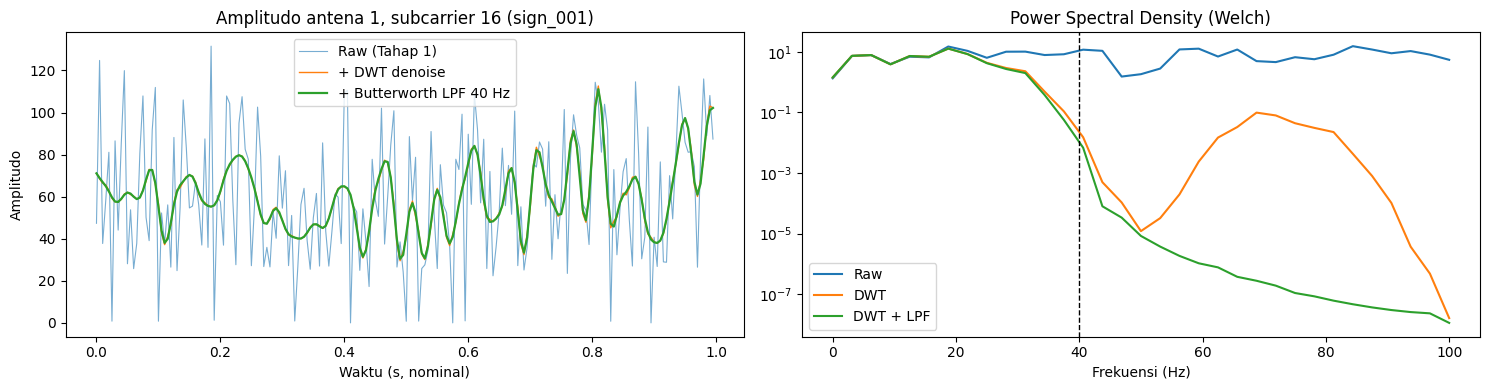

In [ ]:
from scipy.signal import welch
P.STEP_LOG.clear()
i0 = 0
H1 = H_ALL[i0:i0 + 1]                                   # (1, T, 3, 30)
amp1, pha1 = P.extract_amplitude_phase(H1)               # Tahap 1
ANT, SUB = 0, 15
a_raw = amp1[0, :, ANT, SUB]
a_dwt = P.dwt_denoise(a_raw[None, :], CFG['DWT_WAVELET'], CFG['DWT_LEVEL'], axis=1)[0]
a_lpf = P.butterworth_lowpass(a_dwt[None, :], CFG['FS'], CFG['LPF_CUTOFF'], CFG['LPF_ORDER'], axis=1)[0]
t = np.arange(T_LEN) / CFG['FS']

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(t, a_raw, lw=.8, alpha=.6, label='Raw (Tahap 1)')
ax[0].plot(t, a_dwt, lw=1, label='+ DWT denoise')
ax[0].plot(t, a_lpf, lw=1.6, label=f'+ Butterworth LPF {CFG["LPF_CUTOFF"]:.0f} Hz')
ax[0].set(title=f'Amplitudo antena {ANT+1}, subcarrier {SUB+1} ({CLASSES[y_all[i0]]})', xlabel='Waktu (s, nominal)', ylabel='Amplitudo'); ax[0].legend()
for sig, lab in [(a_raw, 'Raw'), (a_dwt, 'DWT'), (a_lpf, 'DWT + LPF')]:
    f, pxx = welch(sig - sig.mean(), fs=CFG['FS'], nperseg=64)
    ax[1].semilogy(f, pxx, label=lab)
ax[1].axvline(CFG['LPF_CUTOFF'], ls='--', c='k', lw=1); ax[1].set(title='Power Spectral Density (Welch)', xlabel='Frekuensi (Hz)'); ax[1].legend()
plt.tight_layout(); savefig('prep_step2_filtering.png'); plt.show()

💾 disimpan: /content/wifi-csi-har/outputs/figures/prep_step3_phase_sanitization.png


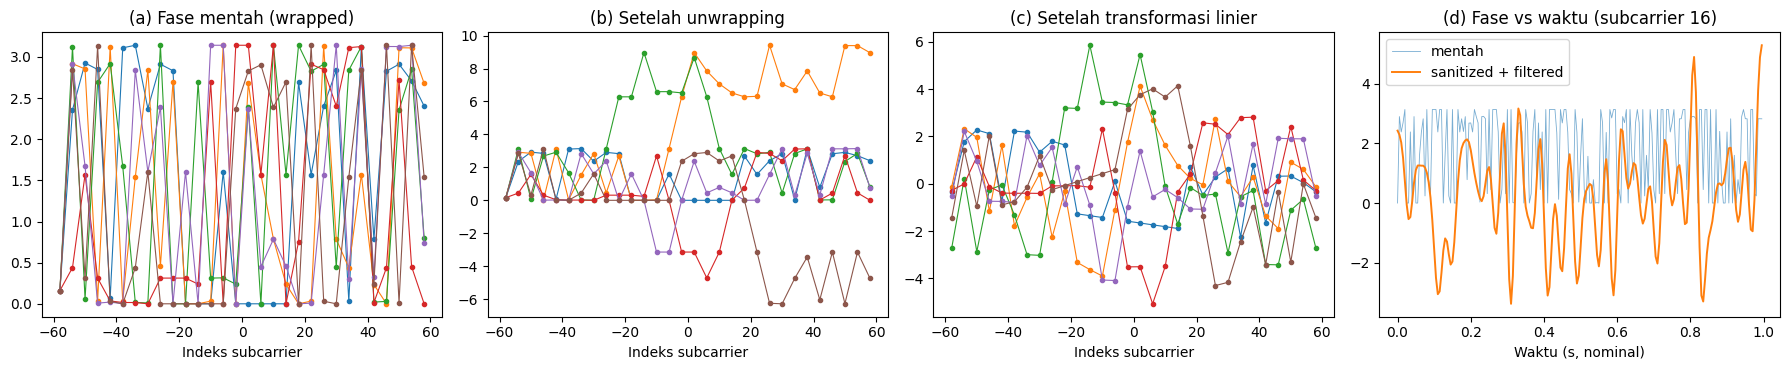

Std fase antar-paket per subcarrier — mentah: 1.271 rad | tersanitasi: 1.886 rad


In [ ]:
pha_san1 = P.sanitize_phase(pha1)                        # Tahap 3
unw1 = np.unwrap(pha1.astype(np.float64), axis=-1)
k = P.SIGNFI_SUBCARRIER_IDX
pk = np.linspace(0, T_LEN - 1, 6).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for p_ in pk:
    ax[0].plot(k, pha1[0, p_, ANT], '.-', lw=.8); ax[1].plot(k, unw1[0, p_, ANT], '.-', lw=.8); ax[2].plot(k, pha_san1[0, p_, ANT], '.-', lw=.8)
ax[0].set_title('(a) Fase mentah (wrapped)'); ax[1].set_title('(b) Setelah unwrapping'); ax[2].set_title('(c) Setelah transformasi linier')
for a_ in ax[:3]: a_.set_xlabel('Indeks subcarrier')
ph_f = P.denoise(pha_san1[:, :, ANT, SUB], CFG)[0]
ax[3].plot(t, pha1[0, :, ANT, SUB], lw=.6, alpha=.6, label='mentah')
ax[3].plot(t, ph_f, lw=1.4, label='sanitized + filtered')
ax[3].set(title='(d) Fase vs waktu (subcarrier %d)' % (SUB + 1), xlabel='Waktu (s, nominal)'); ax[3].legend()
plt.tight_layout(); savefig('prep_step3_phase_sanitization.png'); plt.show()
print('Std fase antar-paket per subcarrier — mentah: %.3f rad | tersanitasi: %.3f rad'
      % (pha1[0, :, ANT].std(0).mean(), pha_san1[0, :, ANT].std(0).mean()))

Tensor      : (8, 2, 90, 200) -> (N, Channels[amp,phase], Subcarriers, Time)
Spektrogram : (8, 8, 17, 43) -> (N, 2*N_PCA, Freq bins, Time frames)
💾 disimpan: /content/wifi-csi-har/outputs/figures/prep_step4_feature_structuring.png


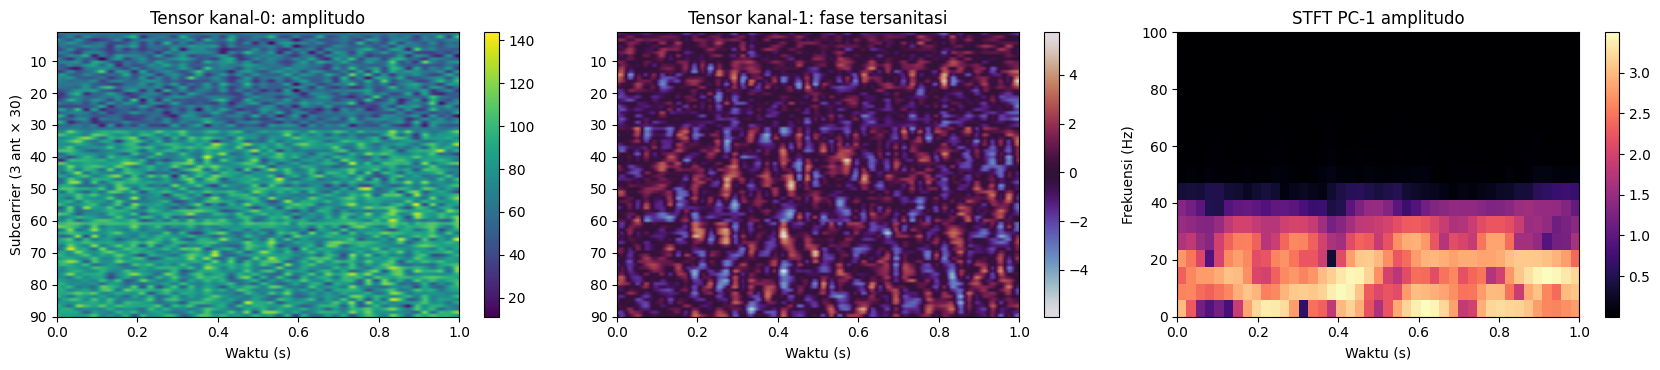

In [ ]:
one = P.preprocess_batch(H_ALL[:8], CFG, ('full',))     # Tahap 1-4 lengkap untuk 8 sampel
Xw, Sw = one['full'], one['S']
print('Tensor      :', Xw.shape, '-> (N, Channels[amp,phase], Subcarriers, Time)')
print('Spektrogram :', Sw.shape, '-> (N, 2*N_PCA, Freq bins, Time frames)')
F_bins = np.fft.rfftfreq(CFG['STFT_NPERSEG'], d=1 / CFG['FS'])
dur = T_LEN / CFG['FS']
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
im = ax[0].imshow(Xw[0, 0], aspect='auto', cmap='viridis', extent=[0, dur, 90, 1]); ax[0].set(title='Tensor kanal-0: amplitudo', xlabel='Waktu (s)', ylabel='Subcarrier (3 ant × 30)'); plt.colorbar(im, ax=ax[0])
im = ax[1].imshow(Xw[0, 1], aspect='auto', cmap='twilight', extent=[0, dur, 90, 1]); ax[1].set(title='Tensor kanal-1: fase tersanitasi', xlabel='Waktu (s)'); plt.colorbar(im, ax=ax[1])
im = ax[2].imshow(Sw[0, 0], aspect='auto', origin='lower', cmap='magma', extent=[0, dur, F_bins[0], F_bins[-1]]); ax[2].set(title='STFT PC-1 amplitudo', xlabel='Waktu (s)', ylabel='Frekuensi (Hz)'); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); savefig('prep_step4_feature_structuring.png'); plt.show()
del one

## 6. Preprocessing seluruh dataset
Pipeline utama (`full`) dijalankan pada semua sampel. Jika `RUN_ABLATION=True`, varian `no_filter`, `no_sanitize`, `raw` juga dibuat untuk ablation study.

In [ ]:
VARIANTS = ['full'] + (['no_filter', 'no_sanitize', 'raw'] if CFG['RUN_ABLATION'] else [])
P.STEP_LOG.clear()
t0 = time.time()
OUT = P.preprocess_dataset(H_ALL, CFG, tuple(VARIANTS))
STEP_TOTAL = dict(P.STEP_LOG)
DATA = {('X_' + k if k != 'S' else 'S'): v for k, v in OUT.items()}
del OUT
print(f'⏱️ preprocessing: {time.time()-t0:.0f} s')
for k_, v_ in DATA.items():
    print(f'{k_:14s} {str(v_.shape):24s} {v_.nbytes/1e9:.2f} GB')

   diproses 5520/5520
⏱️ preprocessing: 85 s
X_full         (5520, 2, 90, 200)       0.79 GB
X_no_filter    (5520, 2, 90, 200)       0.79 GB
X_no_sanitize  (5520, 2, 90, 200)       0.79 GB
X_raw          (5520, 2, 90, 200)       0.79 GB
S              (5520, 8, 17, 43)        0.13 GB


### 6.1 ✅ Audit pipeline — memastikan semua tahap preprocessing terpakai
Sel ini akan **error (AssertionError)** jika ada satu saja tahap wajib yang tidak dijalankan pada data yang masuk ke model.

In [ ]:
REQUIRED = {
    '1_extraction_amp_phase'    : '1. Extraction amplitudo & fase',
    '2a_dwt_denoise'            : '2. Filtering — DWT denoising',
    '2b_butterworth_lowpass'    : '2. Filtering — Butterworth low-pass',
    '3a_phase_unwrap'           : '3. Phase sanitization — unwrapping',
    '3b_phase_linear_transform' : '3. Phase sanitization — transformasi linier',
    '4a_tensor_structuring'     : '4. Feature structuring — tensor (B,C,S,T)',
    '4b_pca_stft_spectrogram'   : '4. Feature structuring — PCA + STFT spektrogram',
}
audit = pd.DataFrame({'Tahap': list(REQUIRED.values()),
                      'Jumlah pemanggilan': [int(STEP_TOTAL.get(k_, 0)) for k_ in REQUIRED]})
audit['Status'] = np.where(audit['Jumlah pemanggilan'] > 0, '✅ dipakai', '❌ TIDAK dipakai')
display(audit)
assert (audit['Jumlah pemanggilan'] > 0).all(), 'Ada tahap preprocessing yang tidak terpakai!'
# bukti tambahan: data model berbeda dari data mentah
raw_amp = np.abs(H_ALL[:200]).reshape(200, T_LEN, -1).transpose(0, 2, 1)
print('Selisih rata-rata amplitudo full vs raw  :', float(np.abs(DATA['X_full'][:200, 0] - raw_amp).mean()))
print('Std fase kanal model (sanitized) vs mentah:', float(DATA['X_full'][:200, 1].std()), 'vs', float(np.angle(H_ALL[:200]).std()))
print('\nInput model:')
print('  Baseline 1D-CNN & Proposed CNN-BiLSTM  <- DATA["X_full"]', DATA['X_full'].shape, '(tahap 1+2+3+4a)')
print('  ResNet-2D spektrogram                 <- DATA["S"]     ', DATA['S'].shape, '(tahap 1+2+3+4b)')
audit.to_csv(os.path.join(CFG['OUT_DIR'], 'preprocessing_audit.csv'), index=False)

,Tahap,Jumlah pemanggilan,Status
0,1. Extraction amplitudo & fase,12,✅ dipakai
1,2. Filtering — DWT denoising,36,✅ dipakai
2,2. Filtering — Butterworth low-pass,36,✅ dipakai
3,3. Phase sanitization — unwrapping,12,✅ dipakai
4,3. Phase sanitization — transformasi linier,12,✅ dipakai
5,"4. Feature structuring — tensor (B,C,S,T)",48,✅ dipakai
6,4. Feature structuring — PCA + STFT spektrogram,12,✅ dipakai


Selisih rata-rata amplitudo full vs raw  : 10.819046974182129
Std fase kanal model (sanitized) vs mentah: 1.1287535429000854 vs 1.819761872291565

Input model:
  Baseline 1D-CNN & Proposed CNN-BiLSTM  <- DATA["X_full"] (5520, 2, 90, 200) (tahap 1+2+3+4a)
  ResNet-2D spektrogram                 <- DATA["S"]      (5520, 8, 17, 43) (tahap 1+2+3+4b)


### 6.2 Split train/val/test (stratified per kelas)
Setiap sampel SignFi adalah satu gestur utuh yang sudah tersegmentasi (tidak ada window overlap), sehingga split stratified per sampel aman dari kebocoran data: 14/3/3 sampel per gestur.

In [ ]:
from sklearn.model_selection import train_test_split
idx = np.arange(len(y_all))
tr, tmp = train_test_split(idx, test_size=CFG['SPLIT'][1] + CFG['SPLIT'][2], stratify=y_all, random_state=CFG['SEED'])
va, te = train_test_split(tmp, test_size=CFG['SPLIT'][2] / (CFG['SPLIT'][1] + CFG['SPLIT'][2]), stratify=y_all[tmp], random_state=CFG['SEED'])
IDX = {'train': np.sort(tr), 'val': np.sort(va), 'test': np.sort(te)}
print({k: len(v) for k, v in IDX.items()})
assert not (set(IDX['train']) & set(IDX['test'])) and not (set(IDX['train']) & set(IDX['val']))
np.savez(os.path.join(CFG['OUT_DIR'], 'split_indices.npz'), **IDX)

{'train': 3864, 'val': 828, 'test': 828}


### 6.3 Normalisasi (statistik dari *train set* saja) & DataLoader

In [ ]:
def channel_stats(X, idx, chunk=512):
    # mean/std per (channel, baris) — dirata-rata atas sampel & waktu, hanya dari data train
    s = ss = 0.0; n_ = 0
    for i in range(0, len(idx), chunk):
        x = X[idx[i:i + chunk]].astype(np.float64)
        s = s + x.sum(axis=(0, 3)); ss = ss + (x ** 2).sum(axis=(0, 3)); n_ += x.shape[0] * x.shape[3]
    mean = s / n_; std = np.sqrt(np.maximum(ss / n_ - mean ** 2, 1e-12))
    return mean[..., None].astype(np.float32), (std[..., None] + 1e-6).astype(np.float32)

class CSIDataset(Dataset):
    def __init__(self, X, y, idx, mean, std, channels=None, augment=False):
        self.X, self.y, self.idx, self.ch, self.aug = X, y, idx, channels, augment
        self.mean = mean if channels is None else mean[channels]
        self.std = std if channels is None else std[channels]
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        x = self.X[j] if self.ch is None else self.X[j][self.ch]
        x = torch.from_numpy(((x - self.mean) / self.std).astype(np.float32))
        if self.aug:   # augmentasi ringan: scaling per kanal + noise gaussian
            x = x * (1 + 0.1 * torch.randn(x.shape[0], 1, 1)) + 0.05 * torch.randn_like(x)
        return x, int(self.y[j])

def make_loaders(X, channels=None, seed=CFG['SEED']):
    mean, std = channel_stats(X, IDX['train'])
    g = torch.Generator(); g.manual_seed(seed)
    kw = dict(batch_size=CFG['BATCH'], num_workers=CFG['NUM_WORKERS'], pin_memory=(DEVICE.type == 'cuda'))
    return {
        'train': DataLoader(CSIDataset(X, y_all, IDX['train'], mean, std, channels, CFG['AUGMENT']), shuffle=True, drop_last=True, generator=g, **kw),
        'val'  : DataLoader(CSIDataset(X, y_all, IDX['val'],   mean, std, channels), shuffle=False, **kw),
        'test' : DataLoader(CSIDataset(X, y_all, IDX['test'],  mean, std, channels), shuffle=False, **kw),
    }, (mean, std)

LOADERS_T, NORM_T = make_loaders(DATA['X_full'])   # tensor (B,2,90,T)
LOADERS_S, NORM_S = make_loaders(DATA['S'])        # spektrogram (B,8,F,frames)
xb, yb = next(iter(LOADERS_T['train'])); print('Batch tensor     :', tuple(xb.shape), yb[:8].tolist())
xb, yb = next(iter(LOADERS_S['train'])); print('Batch spektrogram:', tuple(xb.shape))

Batch tensor     : (64, 2, 90, 200) [60, 132, 210, 147, 44, 9, 81, 169]
Batch spektrogram: (64, 8, 17, 43)


### 6.4 Contoh spektrogram STFT beberapa gestur

💾 disimpan: /content/wifi-csi-har/outputs/figures/stft_per_class.png


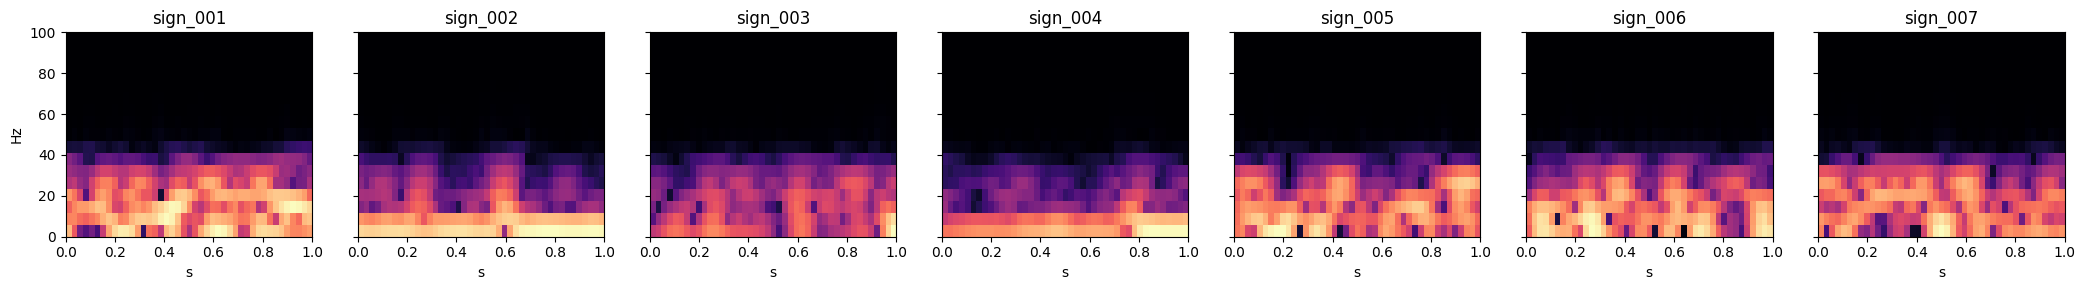

In [ ]:
show = list(range(min(7, N_CLASSES)))
fig, ax = plt.subplots(1, len(show), figsize=(3 * len(show), 3), sharey=True)
ax = np.atleast_1d(ax)
for a_, c in zip(ax, show):
    j = IDX['train'][y_all[IDX['train']] == c]
    a_.imshow(DATA['S'][j[0], 0], aspect='auto', origin='lower', cmap='magma', extent=[0, dur, F_bins[0], F_bins[-1]])
    a_.set_title(CLASSES[c]); a_.set_xlabel('s')
ax[0].set_ylabel('Hz'); plt.tight_layout(); savefig('stft_per_class.png'); plt.show()

## 7. Arsitektur model (`src/models.py`)
| Model | Input | Ide |
|---|---|---|
| **Baseline 1D-CNN** | tensor (2,90,200) → 180 kanal × 200 waktu | konvolusi temporal + global average pooling |
| **Proposed CNN-BiLSTM + Attention** | tensor (2,90,200) | CNN mengekstrak fitur lokal antar-subcarrier, BiLSTM memodelkan dinamika temporal dua arah, *temporal attention* memilih momen paling informatif |
| **ResNet-2D (STFT)** | spektrogram (8,17,43) | memperlakukan pola Doppler (PCA-STFT) sebagai citra |

In [ ]:
%%writefile src/models.py
import torch
import torch.nn as nn
import torch.nn.functional as F


def conv1d_block(cin, cout, k, pool=True, drop=0.1):
    layers = [nn.Conv1d(cin, cout, k, padding=k // 2, bias=False), nn.BatchNorm1d(cout), nn.ReLU(inplace=True)]
    if pool:
        layers.append(nn.MaxPool1d(2))
    layers.append(nn.Dropout(drop))
    return nn.Sequential(*layers)


class Baseline1DCNN(nn.Module):
    """Baseline: subcarrier x kanal dijadikan channel, konvolusi di sumbu waktu."""
    def __init__(self, in_ch=180, n_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            conv1d_block(in_ch, 128, 7), conv1d_block(128, 128, 5),
            conv1d_block(128, 256, 3), conv1d_block(256, 256, 3, pool=False))
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):                      # x: (B, C, S, T)
        x = x.flatten(1, 2)                    # (B, C*S, T)
        return self.head(self.features(x))


class CNNBiLSTMAttention(nn.Module):
    """Proposed: CNN (fitur lokal) -> BiLSTM (temporal) -> temporal attention pooling."""
    def __init__(self, in_ch=180, n_classes=7, conv_ch=128, hidden=128, layers=2):
        super().__init__()
        self.cnn = nn.Sequential(conv1d_block(in_ch, conv_ch, 5), conv1d_block(conv_ch, conv_ch, 5))
        self.lstm = nn.LSTM(conv_ch, hidden, num_layers=layers, batch_first=True, bidirectional=True, dropout=0.3)
        self.attn = nn.Sequential(nn.Linear(2 * hidden, 128), nn.Tanh(), nn.Linear(128, 1))
        self.head = nn.Sequential(nn.LayerNorm(2 * hidden), nn.Dropout(0.3), nn.Linear(2 * hidden, n_classes))
        self.last_attention = None

    def forward(self, x):                      # (B, C, S, T)
        h = self.cnn(x.flatten(1, 2))          # (B, conv_ch, T/4)
        h, _ = self.lstm(h.transpose(1, 2))    # (B, T/4, 2H)
        w = torch.softmax(self.attn(h).squeeze(-1).float(), dim=1)   # (B, T/4)
        self.last_attention = w.detach()
        z = (h * w.unsqueeze(-1).to(h.dtype)).sum(1)
        return self.head(z)


class ResBlock2d(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(cout)
        self.sc = nn.Sequential() if (stride == 1 and cin == cout) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        return F.relu(self.b2(self.c2(F.relu(self.b1(self.c1(x))))) + self.sc(x))


class SpecResNet(nn.Module):
    """ResNet kecil untuk spektrogram PCA-STFT (B, 2*N_PCA, F, T)."""
    def __init__(self, in_ch=8, n_classes=7):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_ch, 32, 3, 1, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.layers = nn.Sequential(ResBlock2d(32, 32), ResBlock2d(32, 64, 2), ResBlock2d(64, 128, 2), nn.Dropout2d(0.1))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.layers(self.stem(x)))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Writing src/models.py


## 8. Training & evaluation utilities (`src/trainer.py`)
AdamW + cosine LR, label smoothing, gradient clipping, mixed precision (GPU), early stopping berdasar akurasi validasi, checkpoint model terbaik.

In [ ]:
%%writefile src/trainer.py
import copy
import time

import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score


def _autocast(device):
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda"))


def _grad_scaler(device):
    try:
        return torch.amp.GradScaler(device.type, enabled=(device.type == "cuda"))
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


def run_epoch(model, loader, criterion, device, optimizer=None, scaler=None, clip=1.0):
    train = optimizer is not None
    model.train(train)
    tot, preds, trues = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(train), _autocast(device):
            out = model(x)
            loss = criterion(out.float(), y)
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), clip)
            scaler.step(optimizer)
            scaler.update()
        tot += loss.item() * x.size(0)
        preds.append(out.argmax(1).cpu()); trues.append(y.cpu())
    p, t = torch.cat(preds).numpy(), torch.cat(trues).numpy()
    return tot / len(t), accuracy_score(t, p), f1_score(t, p, average="macro")


def fit(model, loaders, device, epochs=40, lr=1e-3, wd=1e-4, patience=10, label_smoothing=0.05,
        ckpt_path=None, verbose=True):
    model.to(device)
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=lr * 0.01)
    scaler = _grad_scaler(device)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1", "lr"]}
    best, best_state, best_ep, wait = (-1, np.inf), None, 0, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        tl, ta, _ = run_epoch(model, loaders["train"], crit, device, opt, scaler)
        vl, va, vf = run_epoch(model, loaders["val"], crit, device)
        hist["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"], [tl, ta, vl, va, vf]):
            hist[k].append(v)
        improved = (va > best[0]) or (va == best[0] and vl < best[1])
        if improved:
            best, best_ep, wait = (va, vl), ep, 0
            best_state = copy.deepcopy(model.state_dict())
            if ckpt_path:
                torch.save(best_state, ckpt_path)
        else:
            wait += 1
        if verbose and (ep == 1 or ep % 5 == 0 or improved):
            print(f"ep {ep:3d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} f1 {vf:.3f}"
                  + ("  *" if improved else ""))
        if wait >= patience:
            if verbose:
                print(f"Early stopping di epoch {ep} (best epoch {best_ep})")
            break
    model.load_state_dict(best_state)
    return model, hist, {"best_epoch": best_ep, "best_val_acc": best[0], "train_time_s": time.time() - t0}


@torch.no_grad()
def predict(model, loader, device):
    model.eval().to(device)
    P, Y = [], []
    for x, y in loader:
        with _autocast(device):
            P.append(torch.softmax(model(x.to(device)).float(), 1).cpu())
        Y.append(y)
    probs = torch.cat(P).numpy()
    return torch.cat(Y).numpy(), probs.argmax(1), probs


@torch.no_grad()
def latency_ms(model, sample, device, n=50):
    model.eval().to(device); x = sample.to(device)
    for _ in range(5):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n):
        model(x)
    if device.type == "cuda":
        torch.cuda.synchronize()
    return (time.time() - t0) / n / x.shape[0] * 1000

Writing src/trainer.py


In [ ]:
import src.models as M, src.trainer as TR
importlib.reload(M); importlib.reload(TR)
CKPT_DIR = os.path.join(CFG['OUT_DIR'], 'checkpoints'); os.makedirs(CKPT_DIR, exist_ok=True)

MODEL_ZOO = {
    'Baseline 1D-CNN'           : (lambda: M.Baseline1DCNN(in_ch=2 * 90, n_classes=N_CLASSES),       'tensor'),
    'Proposed CNN-BiLSTM-Attn'  : (lambda: M.CNNBiLSTMAttention(in_ch=2 * 90, n_classes=N_CLASSES),  'tensor'),
    'ResNet-2D (STFT)'          : (lambda: M.SpecResNet(in_ch=DATA['S'].shape[1], n_classes=N_CLASSES), 'spec'),
}
for name, (fn, kind) in MODEL_ZOO.items():
    print(f'{name:28s} input={kind:7s} params={M.count_params(fn()):,}')

Baseline 1D-CNN              input=tensor  params=610,580
Proposed CNN-BiLSTM-Attn     input=tensor  params=961,557
ResNet-2D (STFT)             input=spec    params=344,404


## 9. Training & perbandingan model

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, top_k_accuracy_score, confusion_matrix
RESULTS, HISTORY, PREDS, TRAINED = [], {}, {}, {}
for name, (fn, kind) in MODEL_ZOO.items():
    print('\n' + '=' * 90 + f'\n▶ {name}\n' + '=' * 90)
    set_seed(CFG['SEED'])
    loaders = LOADERS_T if kind == 'tensor' else LOADERS_S
    model = fn()
    ckpt = os.path.join(CKPT_DIR, name.split()[0].lower() + '_' + kind + '.pt')
    model, hist, info = TR.fit(model, loaders, DEVICE, CFG['EPOCHS'], CFG['LR'], CFG['WD'], CFG['PATIENCE'],
                               CFG['LABEL_SMOOTHING'], ckpt_path=ckpt)
    y_t, y_p, prob = TR.predict(model, loaders['test'], DEVICE)
    p_, r_, f_, _ = precision_recall_fscore_support(y_t, y_p, average='macro', zero_division=0)
    top5 = top_k_accuracy_score(y_t, prob, k=min(5, N_CLASSES), labels=np.arange(N_CLASSES))
    lat = TR.latency_ms(model, next(iter(loaders['test']))[0][:32], DEVICE)
    RESULTS.append({'Model': name, 'Input': kind, 'Params': M.count_params(model), 'Best epoch': info['best_epoch'],
                    'Val Acc': info['best_val_acc'], 'Test Acc (top-1)': accuracy_score(y_t, y_p), 'Test Top-5': top5,
                    'Precision (macro)': p_, 'Recall (macro)': r_, 'F1 (macro)': f_,
                    'Train time (s)': info['train_time_s'], 'Latency (ms/sampel)': lat})
    HISTORY[name], PREDS[name], TRAINED[name] = hist, (y_t, y_p, prob), model
    print(f"TEST → top-1 {RESULTS[-1]['Test Acc (top-1)']:.4f} | top-5 {top5:.4f} | macro-F1 {f_:.4f}")

RES_DF = pd.DataFrame(RESULTS).set_index('Model')
RES_DF.to_csv(os.path.join(CFG['OUT_DIR'], 'model_comparison.csv'))
fmt = {c: '{:.4f}' for c in RES_DF.columns if RES_DF[c].dtype == float}
fmt.update({'Params': '{:,}', 'Train time (s)': '{:.0f}', 'Latency (ms/sampel)': '{:.3f}'})
display(RES_DF.style.format(fmt).highlight_max(subset=['Test Acc (top-1)', 'F1 (macro)'], color='#c6f5c6'))


▶ Baseline 1D-CNN
ep   1 | train loss 5.028 acc 0.032 | val loss 4.233 acc 0.112 f1 0.056  *
ep   2 | train loss 3.981 acc 0.168 | val loss 3.471 acc 0.382 f1 0.292  *
ep   3 | train loss 3.197 acc 0.416 | val loss 2.771 acc 0.605 f1 0.542  *
ep   4 | train loss 2.527 acc 0.652 | val loss 2.138 acc 0.807 f1 0.787  *
ep   5 | train loss 2.031 acc 0.796 | val loss 1.757 acc 0.855 f1 0.836  *
ep   6 | train loss 1.759 acc 0.856 | val loss 1.562 acc 0.890 f1 0.875  *
ep   7 | train loss 1.615 acc 0.872 | val loss 1.468 acc 0.895 f1 0.881  *
ep   9 | train loss 1.476 acc 0.889 | val loss 1.345 acc 0.911 f1 0.898  *
ep  10 | train loss 1.418 acc 0.903 | val loss 1.298 acc 0.912 f1 0.899  *
ep  11 | train loss 1.381 acc 0.909 | val loss 1.314 acc 0.920 f1 0.912  *
ep  12 | train loss 1.340 acc 0.918 | val loss 1.245 acc 0.940 f1 0.929  *
ep  14 | train loss 1.271 acc 0.941 | val loss 1.182 acc 0.960 f1 0.955  *
ep  15 | train loss 1.242 acc 0.952 | val loss 1.149 acc 0.963 f1 0.957  *
ep  16

,Input,Params,Best epoch,Val Acc,Test Acc (top-1),Test Top-5,Precision (macro),Recall (macro),F1 (macro),Train time (s),Latency (ms/sampel)
Model,,,,,,,,,,,
Baseline 1D-CNN,tensor,"610,580",40,0.9952,0.9903,1.0000,0.9935,0.9903,0.9898,153,0.068
Proposed CNN-BiLSTM-Attn,tensor,"961,557",48,0.9879,0.9891,1.0000,0.9885,0.9891,0.9878,173,0.132
ResNet-2D (STFT),spec,"344,404",40,0.3092,0.2935,0.5483,0.3077,0.2935,0.2839,118,0.081


### 9.1 Kurva training (loss & accuracy)

💾 disimpan: /content/wifi-csi-har/outputs/figures/training_curves.png


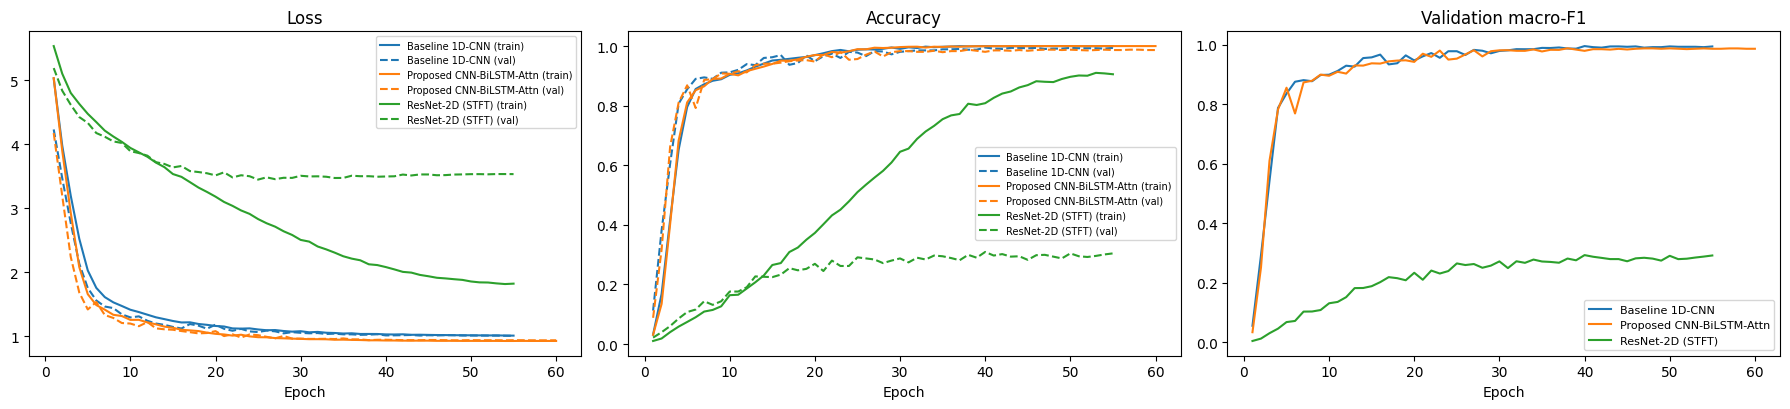

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
for name, h in HISTORY.items():
    ep = np.arange(1, len(h['train_loss']) + 1)
    l, = ax[0].plot(ep, h['train_loss'], label=f'{name} (train)')
    ax[0].plot(ep, h['val_loss'], '--', c=l.get_color(), label=f'{name} (val)')
    ax[1].plot(ep, h['train_acc'], c=l.get_color(), label=f'{name} (train)')
    ax[1].plot(ep, h['val_acc'], '--', c=l.get_color(), label=f'{name} (val)')
    ax[2].plot(ep, h['val_f1'], c=l.get_color(), label=name)
ax[0].set(title='Loss', xlabel='Epoch'); ax[1].set(title='Accuracy', xlabel='Epoch'); ax[2].set(title='Validation macro-F1', xlabel='Epoch')
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7); ax[2].legend(fontsize=8)
plt.tight_layout(); savefig('training_curves.png'); plt.show()

### 9.2 Confusion matrix (test set)
Dengan 276 kelas, confusion matrix penuh ditampilkan sebagai heatmap, ditambah confusion matrix *zoom* 20 kelas pertama dan tabel pasangan gestur yang paling sering tertukar.

💾 disimpan: /content/wifi-csi-har/outputs/figures/confusion_matrices_full.png


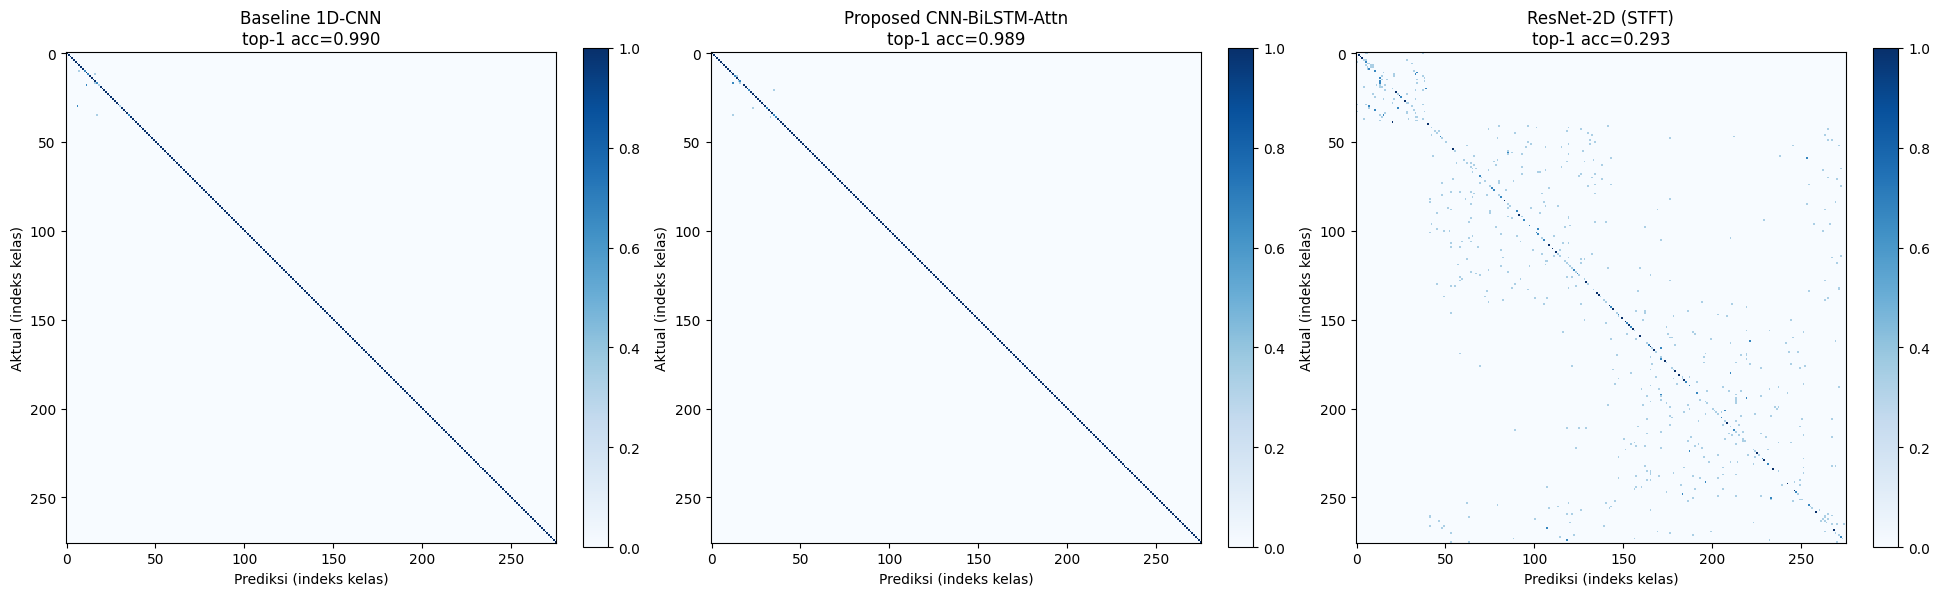

💾 disimpan: /content/wifi-csi-har/outputs/figures/confusion_matrix_zoom.png


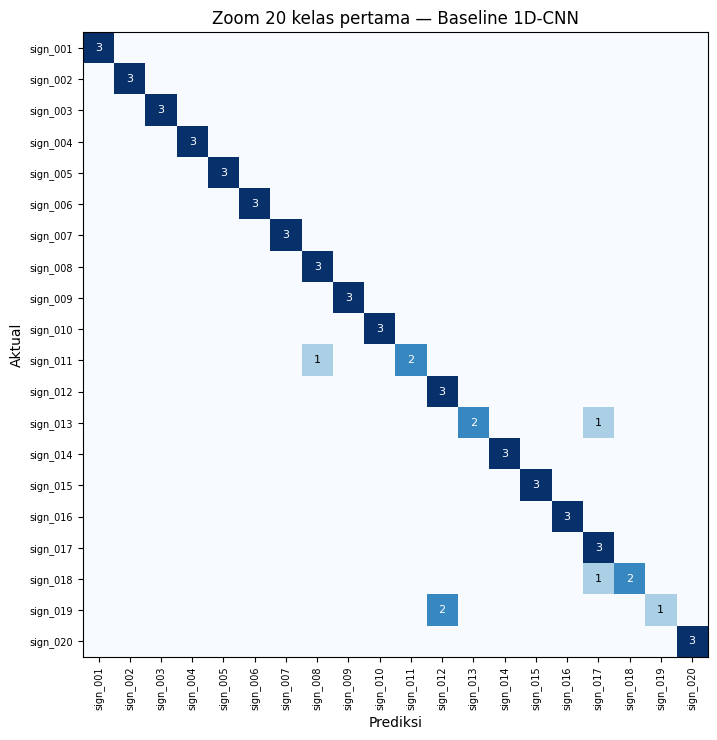

,Aktual,Diprediksi sebagai,Jumlah
0,sign_019,sign_012,2
1,sign_031,sign_007,2
2,sign_018,sign_017,1
3,sign_013,sign_017,1
4,sign_011,sign_008,1
5,sign_036,sign_018,1


In [ ]:
fig, ax = plt.subplots(1, len(PREDS), figsize=(6.5 * len(PREDS), 5.8))
ax = np.atleast_1d(ax)
for a_, (name, (y_t, y_p, _)) in zip(ax, PREDS.items()):
    cm = confusion_matrix(y_t, y_p, labels=range(N_CLASSES))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    im = a_.imshow(cmn, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
    a_.set(title=f'{name}\ntop-1 acc={accuracy_score(y_t, y_p):.3f}', xlabel='Prediksi (indeks kelas)', ylabel='Aktual (indeks kelas)')
    plt.colorbar(im, ax=a_, fraction=.046)
plt.tight_layout(); savefig('confusion_matrices_full.png'); plt.show()

best_name = RES_DF['Test Acc (top-1)'].idxmax()
y_t, y_p, _ = PREDS[best_name]
Z = min(20, N_CLASSES)
cm = confusion_matrix(y_t, y_p, labels=range(N_CLASSES))[:Z, :Z]
fig, a_ = plt.subplots(figsize=(9, 7.5))
a_.imshow(cm, cmap='Blues')
for i_ in range(Z):
    for j_ in range(Z):
        if cm[i_, j_]: a_.text(j_, i_, cm[i_, j_], ha='center', va='center', fontsize=8, color='white' if cm[i_, j_] > 1 else 'black')
a_.set_xticks(range(Z)); a_.set_xticklabels(CLASSES[:Z], rotation=90, fontsize=7); a_.set_yticks(range(Z)); a_.set_yticklabels(CLASSES[:Z], fontsize=7)
a_.set(title=f'Zoom {Z} kelas pertama — {best_name}', xlabel='Prediksi', ylabel='Aktual')
plt.tight_layout(); savefig('confusion_matrix_zoom.png'); plt.show()

cmf = confusion_matrix(y_t, y_p, labels=range(N_CLASSES)); np.fill_diagonal(cmf, 0)
pairs = np.dstack(np.unravel_index(np.argsort(cmf.ravel())[::-1][:15], cmf.shape))[0]
display(pd.DataFrame([(CLASSES[a], CLASSES[b], cmf[a, b]) for a, b in pairs if cmf[a, b] > 0],
                     columns=['Aktual', 'Diprediksi sebagai', 'Jumlah']))

💾 disimpan: /content/wifi-csi-har/outputs/figures/model_comparison_bar.png


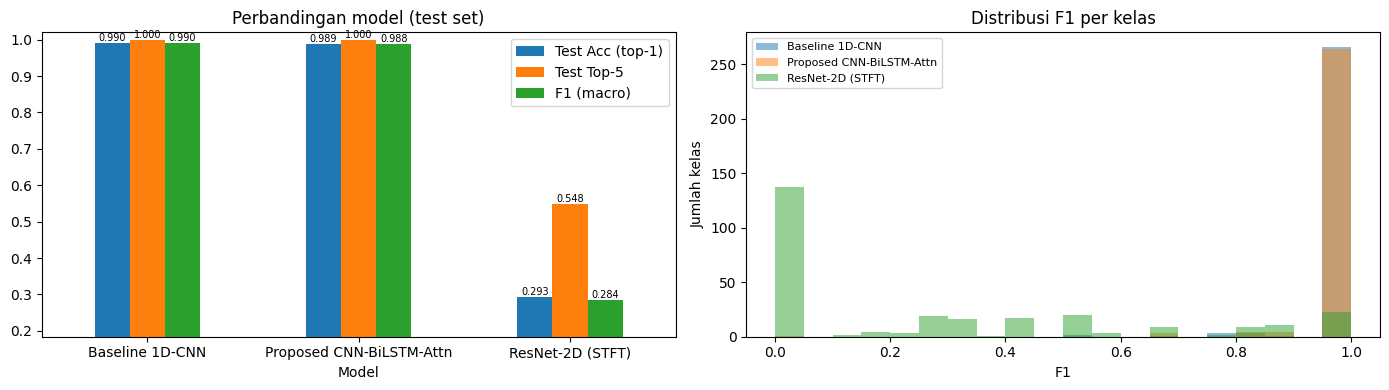

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cols = ['Test Acc (top-1)', 'Test Top-5', 'F1 (macro)']
RES_DF[cols].plot.bar(ax=ax[0], rot=0)
ax[0].set(ylim=(max(0, RES_DF[cols].values.min() - .1), 1.02), title='Perbandingan model (test set)')
for c_ in ax[0].containers: ax[0].bar_label(c_, fmt='%.3f', fontsize=7)
for n, (y_t, y_p, _) in PREDS.items():
    f1c = precision_recall_fscore_support(y_t, y_p, labels=range(N_CLASSES), zero_division=0)[2]
    ax[1].hist(f1c, bins=20, range=(0, 1), alpha=.5, label=n)
ax[1].set(title='Distribusi F1 per kelas', xlabel='F1', ylabel='Jumlah kelas'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('model_comparison_bar.png'); plt.show()

### 9.3 Interpretasi: bobot temporal attention model proposed
Menunjukkan bagian waktu mana pada sinyal CSI yang paling “diperhatikan” model.

💾 disimpan: /content/wifi-csi-har/outputs/figures/attention_weights.png


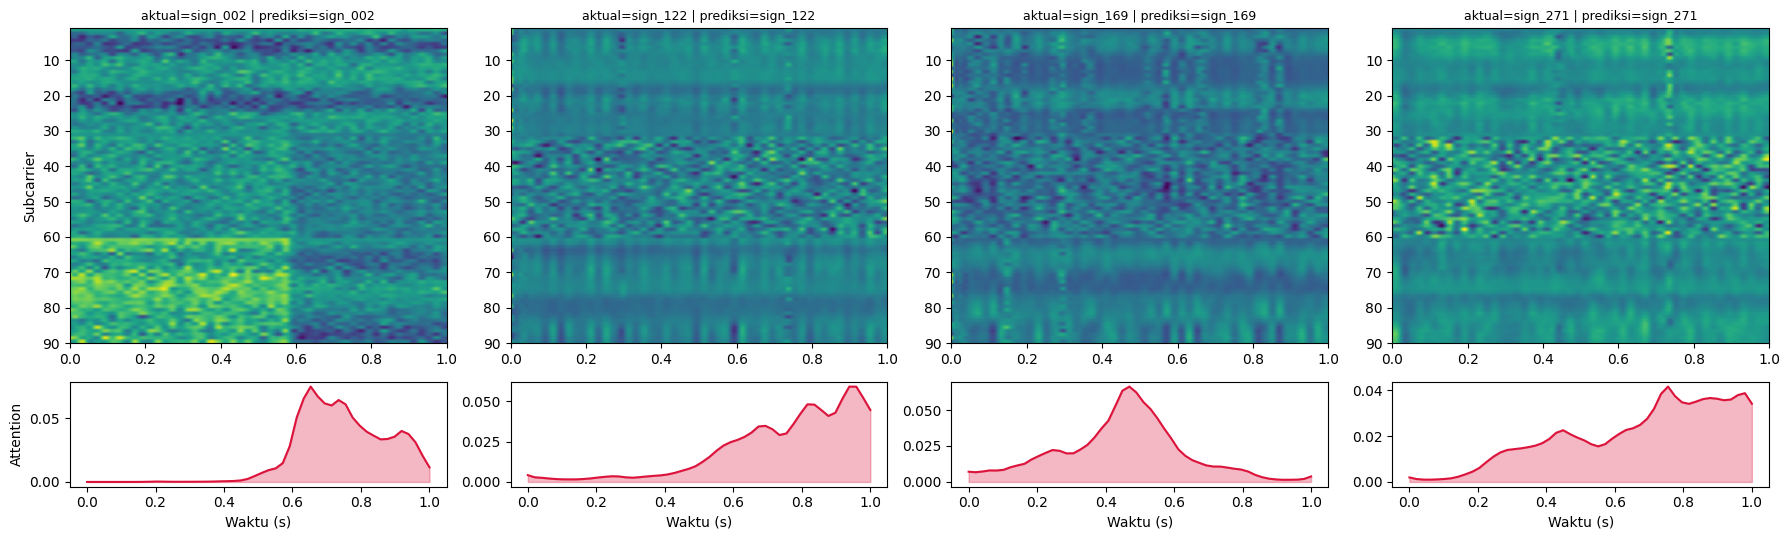

In [ ]:
prop = TRAINED['Proposed CNN-BiLSTM-Attn'].eval()
ds_test = LOADERS_T['test'].dataset
fig, ax = plt.subplots(2, 4, figsize=(18, 5.5), gridspec_kw={'height_ratios': [3, 1]})
for col, ii in enumerate(np.linspace(0, len(ds_test) - 1, 4).astype(int)):
    x, yy = ds_test[ii]
    with torch.no_grad():
        pr = prop(x[None].to(DEVICE)).argmax(1).item()
    w = prop.last_attention[0].cpu().numpy()
    ax[0, col].imshow(x[0].numpy(), aspect='auto', cmap='viridis', extent=[0, dur, 90, 1])
    ax[0, col].set_title(f'aktual={CLASSES[yy]} | prediksi={CLASSES[pr]}', fontsize=9)
    tt = np.linspace(0, dur, len(w))
    ax[1, col].plot(tt, w, c='crimson'); ax[1, col].fill_between(tt, w, alpha=.3, color='crimson'); ax[1, col].set_xlabel('Waktu (s)')
ax[0, 0].set_ylabel('Subcarrier'); ax[1, 0].set_ylabel('Attention')
plt.tight_layout(); savefig('attention_weights.png'); plt.show()

## 10. Ablation study — kontribusi tiap tahap preprocessing
Model proposed (CNN-BiLSTM-Attn) dilatih ulang dengan input berbeda; split & hyperparameter identik. Setiap konfigurasi diulang dengan beberapa seed (`ABL_SEEDS`) → dilaporkan **mean ± std**.

| Konfigurasi | Tahap 1 | Tahap 2 (DWT+LPF) | Tahap 3 (sanitization) | Kanal |
|---|---|---|---|---|
| Full pipeline | ✔ | ✔ | ✔ | amp + fase |
| Amplitudo saja | ✔ | ✔ | – | amp |
| Fase saja (tersanitasi) | ✔ | ✔ | ✔ | fase |
| Tanpa phase sanitization | ✔ | ✔ | ✘ | amp + fase mentah |
| Tanpa filtering | ✔ | ✘ | ✔ | amp + fase |
| Raw | ✔ | ✘ | ✘ | amp + fase mentah |

In [ ]:
if CFG['RUN_ABLATION']:
    ABL_CFGS = {
        'Full pipeline'              : ('X_full', None),
        'Amplitudo saja'             : ('X_full', [0]),
        'Fase saja (tersanitasi)'    : ('X_full', [1]),
        'Tanpa phase sanitization'   : ('X_no_sanitize', None),
        'Tanpa filtering'            : ('X_no_filter', None),
        'Raw (tanpa filter & sanit.)': ('X_raw', None),
    }
    ABL_ROWS, ABL_HIST = [], {}
    for name, (key, ch) in ABL_CFGS.items():
        for seed in CFG['ABL_SEEDS']:
            set_seed(seed)
            loaders, _ = make_loaders(DATA[key], channels=ch, seed=seed)
            model = M.CNNBiLSTMAttention(in_ch=(len(ch) if ch else 2) * 90, n_classes=N_CLASSES)
            model, hist, info = TR.fit(model, loaders, DEVICE, CFG['ABL_EPOCHS'], CFG['LR'], CFG['WD'],
                                       CFG['PATIENCE'], CFG['LABEL_SMOOTHING'], verbose=False)
            y_t, y_p, _ = TR.predict(model, loaders['test'], DEVICE)
            f1m = precision_recall_fscore_support(y_t, y_p, average='macro', zero_division=0)[2]
            ABL_ROWS.append(dict(Konfigurasi=name, seed=seed, test_acc=accuracy_score(y_t, y_p), test_f1=f1m))
            ABL_HIST[(name, seed)] = hist
            print(f'{name:30s} seed={seed:<5d} acc={ABL_ROWS[-1]["test_acc"]:.4f}  f1={f1m:.4f}  (best ep {info["best_epoch"]})')
            del model, loaders
            if DEVICE.type == 'cuda': torch.cuda.empty_cache()
    ABL_DF = pd.DataFrame(ABL_ROWS)
    ABL_SUM = ABL_DF.groupby('Konfigurasi', sort=False).agg(acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
                                                            f1_mean=('test_f1', 'mean'), f1_std=('test_f1', 'std'))
    ABL_SUM['Δacc vs full'] = ABL_SUM.acc_mean - ABL_SUM.loc['Full pipeline', 'acc_mean']
    ABL_DF.to_csv(os.path.join(CFG['OUT_DIR'], 'ablation_runs.csv'), index=False)
    ABL_SUM.to_csv(os.path.join(CFG['OUT_DIR'], 'ablation_summary.csv'))
    display(ABL_SUM.style.format('{:.4f}', na_rep='-').background_gradient(subset=['acc_mean'], cmap='Greens'))
else:
    print('RUN_ABLATION=False → dilewati')

Full pipeline                  seed=42    acc=0.9855  f1=0.9840  (best ep 36)
Full pipeline                  seed=2026  acc=0.9879  f1=0.9872  (best ep 33)
Amplitudo saja                 seed=42    acc=0.9940  f1=0.9938  (best ep 36)
Amplitudo saja                 seed=2026  acc=0.9964  f1=0.9959  (best ep 32)
Fase saja (tersanitasi)        seed=42    acc=0.9239  f1=0.9200  (best ep 36)
Fase saja (tersanitasi)        seed=2026  acc=0.9167  f1=0.9158  (best ep 32)
Tanpa phase sanitization       seed=42    acc=0.9867  f1=0.9855  (best ep 32)
Tanpa phase sanitization       seed=2026  acc=0.9928  f1=0.9925  (best ep 34)
Tanpa filtering                seed=42    acc=0.9783  f1=0.9783  (best ep 26)
Tanpa filtering                seed=2026  acc=0.9879  f1=0.9873  (best ep 38)
Raw (tanpa filter & sanit.)    seed=42    acc=0.9952  f1=0.9951  (best ep 40)
Raw (tanpa filter & sanit.)    seed=2026  acc=0.9915  f1=0.9914  (best ep 39)


,acc_mean,acc_std,f1_mean,f1_std,Δacc vs full
Konfigurasi,,,,,
Full pipeline,0.9867,0.0017,0.9856,0.0023,0.0000
Amplitudo saja,0.9952,0.0017,0.9948,0.0015,0.0085
Fase saja (tersanitasi),0.9203,0.0051,0.9179,0.0029,-0.0664
Tanpa phase sanitization,0.9897,0.0043,0.9890,0.0050,0.0030
Tanpa filtering,0.9831,0.0068,0.9828,0.0063,-0.0036
Raw (tanpa filter & sanit.),0.9934,0.0026,0.9933,0.0026,0.0066


💾 disimpan: /content/wifi-csi-har/outputs/figures/ablation.png


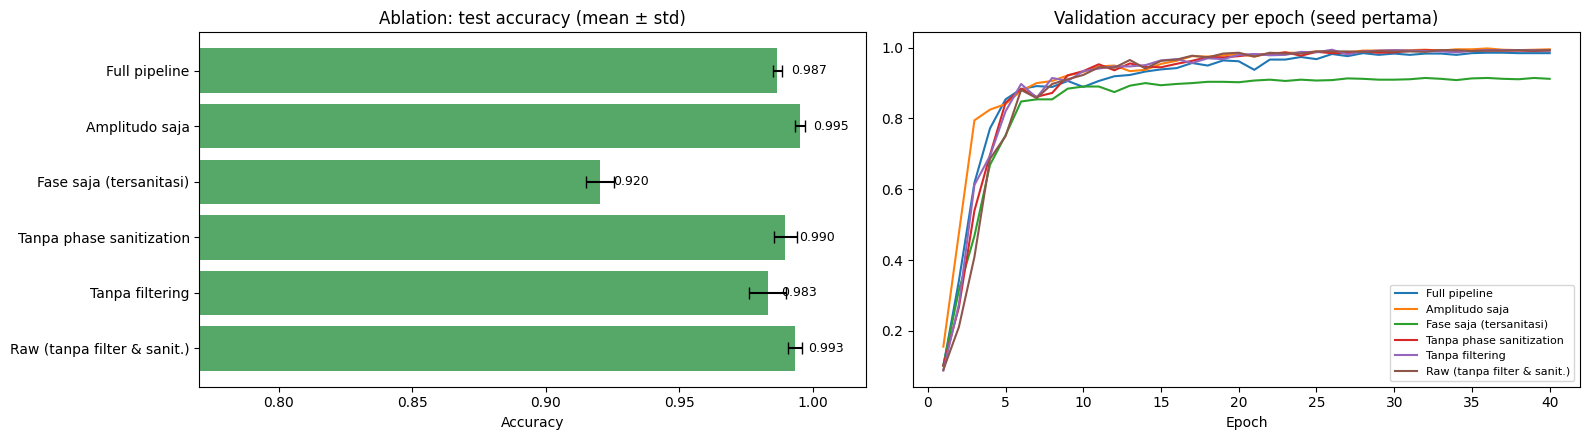

In [ ]:
if CFG['RUN_ABLATION']:
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
    s_ = ABL_SUM.fillna(0)
    ax[0].barh(s_.index[::-1], s_.acc_mean[::-1], xerr=s_.acc_std[::-1], color='#55a868', capsize=4)
    for i_, v_ in enumerate(s_.acc_mean[::-1]): ax[0].text(v_ + .005, i_, f'{v_:.3f}', va='center', fontsize=9)
    ax[0].set(xlim=(max(0, s_.acc_mean.min() - .15), 1.02), title='Ablation: test accuracy (mean ± std)', xlabel='Accuracy')
    for name in ABL_CFGS:
        h = ABL_HIST[(name, CFG['ABL_SEEDS'][0])]
        ax[1].plot(np.arange(1, len(h['val_acc']) + 1), h['val_acc'], label=name)
    ax[1].set(title='Validation accuracy per epoch (seed pertama)', xlabel='Epoch'); ax[1].legend(fontsize=8)
    plt.tight_layout(); savefig('ablation.png'); plt.show()

## 11. Demo inferensi end-to-end
Fungsi `predict_raw_csi()` menerima **CSI kompleks mentah** satu gestur (200×3×30) → menjalankan seluruh pipeline preprocessing (tahap 1–4) → normalisasi → prediksi top-5. Contoh memakai sampel *test set* (tidak pernah dilihat model saat training).

Sampel #5514: aktual=sign_271     prediksi=sign_271     ✅  (24.1 ms termasuk preprocessing)
Sampel #436: aktual=sign_161     prediksi=sign_161     ✅  (23.0 ms termasuk preprocessing)
Sampel #901: aktual=sign_074     prediksi=sign_074     ✅  (21.2 ms termasuk preprocessing)
Sampel #2583: aktual=sign_100     prediksi=sign_100     ✅  (21.0 ms termasuk preprocessing)
💾 disimpan: /content/wifi-csi-har/outputs/figures/demo_inference.png


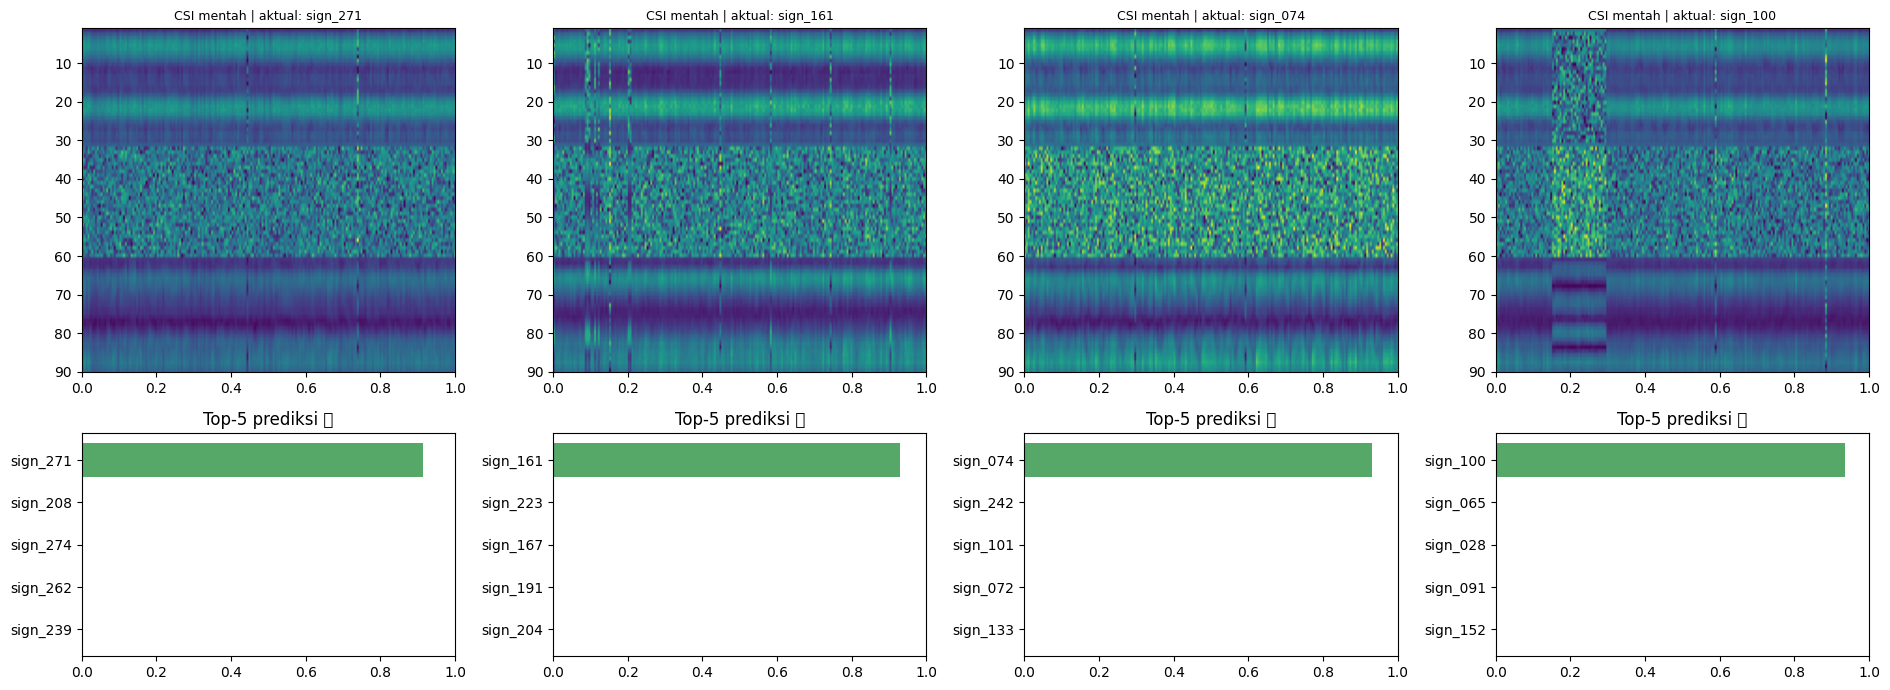

In [ ]:
NORM_MEAN, NORM_STD = NORM_T
def predict_raw_csi(H_raw, model=TRAINED['Proposed CNN-BiLSTM-Attn'], topk=5):
    t0 = time.time()
    X = P.preprocess_batch(H_raw[None] if H_raw.ndim == 3 else H_raw, CFG, ('full',))['full']   # tahap 1-4
    x = torch.from_numpy((X - NORM_MEAN) / NORM_STD).float().to(DEVICE)
    model.eval().to(DEVICE)
    with torch.no_grad():
        prob = torch.softmax(model(x).float(), 1).cpu().numpy()
    ms = (time.time() - t0) * 1000
    top = np.argsort(prob, 1)[:, ::-1][:, :topk]
    return prob, top, ms

rng = np.random.RandomState(7)
demo_idx = rng.choice(IDX['test'], 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(19, 7), gridspec_kw={'height_ratios': [2, 1.3]})
for col, j in enumerate(demo_idx):
    prob, top, ms = predict_raw_csi(H_ALL[j])
    ok = '✅' if top[0, 0] == y_all[j] else '❌'
    print(f'Sampel #{j}: aktual={CLASSES[y_all[j]]:12s} prediksi={CLASSES[top[0,0]]:12s} {ok}  ({ms:.1f} ms termasuk preprocessing)')
    ax[0, col].imshow(np.abs(H_ALL[j]).reshape(T_LEN, -1).T, aspect='auto', cmap='viridis', extent=[0, dur, 90, 1])
    ax[0, col].set_title(f'CSI mentah | aktual: {CLASSES[y_all[j]]}', fontsize=9)
    ax[1, col].barh([CLASSES[c] for c in top[0]][::-1], prob[0, top[0]][::-1],
                    color=['#55a868' if c == y_all[j] else '#c44e52' for c in top[0]][::-1])
    ax[1, col].set(xlim=(0, 1), title=f'Top-5 prediksi {ok}')
plt.tight_layout(); savefig('demo_inference.png'); plt.show()

## 12. Simpan artefak untuk repositori GitHub
Menulis `requirements.txt`, `README.md` (draf), lalu mengemas `src/` dan `outputs/` menjadi zip.

In [ ]:
import scipy, sklearn, pywt as _pywt
req = f'''numpy>={np.__version__.rsplit(".", 1)[0]}
pandas>={pd.__version__.rsplit(".", 1)[0]}
scipy>={scipy.__version__.rsplit(".", 1)[0]}
scikit-learn>={sklearn.__version__.rsplit(".", 1)[0]}
PyWavelets>={_pywt.__version__.rsplit(".", 1)[0]}
torch>={torch.__version__.split("+")[0].rsplit(".", 1)[0]}
h5py
matplotlib
requests
'''
open('requirements.txt', 'w').write(req)
best = RES_DF['Test Acc (top-1)'].idxmax()
try:
    RES_TABLE_MD = RES_DF[['Params', 'Test Acc (top-1)', 'Test Top-5', 'F1 (macro)']].round(4).to_markdown()
except ImportError:
    RES_TABLE_MD = RES_DF[['Params', 'Test Acc (top-1)', 'Test Top-5', 'F1 (macro)']].round(4).to_string()
readme = f'''# WiFi CSI Gesture Recognition (Track A) — SignFi

Pipeline: CSI kompleks (Intel 5300, 3x30, 200 paket/gestur) -> **Extraction** (amp & fase) -> **Filtering** (DWT + Butterworth LPF)
-> **Phase sanitization** (unwrap + transformasi linier) -> **Feature structuring** (tensor 2x90x200 & spektrogram PCA-STFT) -> Deep Learning.

## Struktur
```
src/preprocessing.py   # tahap 1-4 preprocessing CSI
src/models.py          # Baseline 1D-CNN, CNN-BiLSTM-Attention, ResNet-2D (STFT)
src/trainer.py         # training loop, evaluasi, latency
notebook.ipynb         # pipeline lengkap: data -> training -> evaluasi -> ablation -> demo
outputs/               # figur, tabel hasil, checkpoint, config
```

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Unduh `dataset_lab_276_dl.mat` dari https://wm1693.box.com/s/z9vsrn3998n4xyzkpqtj89yclk28eatp (SignFi, Ma et al. 2018)
3. Buka `notebook.ipynb` di Google Colab (GPU) -> Run all.

## Hasil (test set, {N_CLASSES} kelas)
{RES_TABLE_MD}

Model terbaik: **{best}**.
'''
open('README.md', 'w').write(readme)
shutil.make_archive(os.path.join(BASE_DIR, 'wifi_csi_har_repo'), 'zip', PROJECT_DIR)
print('📦', os.path.join(BASE_DIR, 'wifi_csi_har_repo.zip'))
print(readme)
try:
    from google.colab import files
    files.download(os.path.join(BASE_DIR, 'wifi_csi_har_repo.zip'))
except Exception:
    pass

📦 /content/wifi_csi_har_repo.zip
# WiFi CSI Gesture Recognition (Track A) — SignFi

Pipeline: CSI kompleks (Intel 5300, 3x30, 200 paket/gestur) -> **Extraction** (amp & fase) -> **Filtering** (DWT + Butterworth LPF)
-> **Phase sanitization** (unwrap + transformasi linier) -> **Feature structuring** (tensor 2x90x200 & spektrogram PCA-STFT) -> Deep Learning.

## Struktur
```
src/preprocessing.py   # tahap 1-4 preprocessing CSI
src/models.py          # Baseline 1D-CNN, CNN-BiLSTM-Attention, ResNet-2D (STFT)
src/trainer.py         # training loop, evaluasi, latency
notebook.ipynb         # pipeline lengkap: data -> training -> evaluasi -> ablation -> demo
outputs/               # figur, tabel hasil, checkpoint, config
```

## Cara menjalankan
1. `pip install -r requirements.txt`
2. Unduh `dataset_lab_276_dl.mat` dari https://wm1693.box.com/s/z9vsrn3998n4xyzkpqtj89yclk28eatp (SignFi, Ma et al. 2018)
3. Buka `notebook.ipynb` di Google Colab (GPU) -> Run all.

## Hasil (test set, 276 kelas)
|

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>